# 03 — Líneas base y modelos candidatos

Se reserva una sola prueba por grupos de compuesto. La comparación y el tuning usan únicamente entrenamiento y el mismo GroupKFold de cinco pliegues. La mediana por condición es un proxy basado en datos históricos, no una medición del proceso operativo actual del laboratorio.

In [1]:
from pathlib import Path
import os
import sys
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from src.datos import load_snapshot
import warnings
from sklearn.exceptions import ConvergenceWarning
from src.experiments import evaluate_or_reuse_cv_run
from src.pipeline import (
    make_baselines,
    make_default_models,
    make_group_cv,
    make_model_pipeline,
    model_inputs,
    valid_smiles_mask,
)
from src.splits import create_or_load_holdout, stratified_compound_sample

frame, metadata = load_snapshot()
valid = valid_smiles_mask(frame)
all_data = frame.loc[valid & frame["inchikey"].notna()].reset_index(drop=True)
train_full, holdout_full, split_metadata = create_or_load_holdout(all_data, source_sha256=metadata["sha256"])
train_sample, sample_metadata = stratified_compound_sample(train_full, max_compounds=12_000, random_state=42)
model_metadata = {**metadata, "source_rows": metadata["rows"], "rows": len(train_sample), "training_sample_sha256": sample_metadata["sha256"], "sampling_method": sample_metadata["method"], "sampling_seed": sample_metadata["random_state"]}
X_train, y_train, groups_train = model_inputs(train_sample)
cv = make_group_cv(n_splits=5)
print({"filas_totales": len(all_data), "train_completo": len(train_full), "holdout_completo_reservado": len(holdout_full), "muestra_seleccion": len(train_sample), "compuestos_muestra": sample_metadata["compounds"], "grupos_train_sample": groups_train.nunique(), "pliegues": cv.get_n_splits()})
warnings.filterwarnings("ignore", category=ConvergenceWarning)  # el no-convergencia del MLP se discute abajo

{'filas_totales': 152586, 'train_completo': 122370, 'holdout_completo_reservado': 30216, 'muestra_seleccion': 19406, 'compuestos_muestra': 12000, 'grupos_train_sample': 12000, 'pliegues': 5}


Si MLflow ya contiene una corrida terminada con el mismo nombre, fase, familia y hash de la muestra, se reutilizan sus métricas (`reused_from_mlflow=True`) para no duplicar evidencia al ejecutar *Restart + Run All*. Sin esas corridas, el mismo código entrena y registra.

In [2]:
baseline_results = []
for family, estimator in make_baselines().items():
    baseline_results.append(evaluate_or_reuse_cv_run(
        run_name=f"baseline_{family}", phase="baseline", family=family,
        estimator=estimator, X=X_train, y=y_train, groups=groups_train, cv=cv,
        dataset_metadata=model_metadata,
    ))
baseline_table = pd.DataFrame(baseline_results).sort_values("cv_rmse_mean")
display(baseline_table[["family", "reused_from_mlflow", "train_rmse_mean", "cv_rmse_mean", "cv_rmse_std", "cv_mae_mean", "cv_fit_seconds_total"]])

candidate_results = []
for family, regressor in make_default_models().items():
    candidate_results.append(evaluate_or_reuse_cv_run(
        run_name=f"candidate_{family}", phase="candidate", family=family,
        estimator=make_model_pipeline(regressor), X=X_train, y=y_train,
        groups=groups_train, cv=cv, dataset_metadata=model_metadata,
    ))
candidate_table = pd.DataFrame(candidate_results).sort_values("cv_rmse_mean")
display(candidate_table[["family", "reused_from_mlflow", "train_rmse_mean", "cv_rmse_mean", "cv_rmse_std", "rmse_train_cv_gap", "cv_mae_mean", "cv_fit_seconds_total"]])

docs = PROJECT_ROOT / "docs"
docs.mkdir(exist_ok=True)
baseline_table.to_csv(docs / "baselines.csv", index=False)
candidate_table.to_csv(docs / "candidatos.csv", index=False)
print(f"Resultados guardados en {docs}")

,family,reused_from_mlflow,train_rmse_mean,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_fit_seconds_total
1,method_median_proxy,True,3.691914,3.764737,0.404978,2.583680,0.162976
0,naive_median,True,5.826243,5.828258,0.090012,4.875349,0.092283


,family,reused_from_mlflow,train_rmse_mean,cv_rmse_mean,cv_rmse_std,rmse_train_cv_gap,cv_mae_mean,cv_fit_seconds_total
2,hist_gradient_boosting,True,2.132407,2.604109,0.239992,0.471702,1.693492,11.186555
1,random_forest,True,1.119416,2.682672,0.247504,1.563256,1.722910,41.687265
3,mlp,True,2.451082,2.764227,0.204090,0.313145,1.846046,66.093571
4,knn,True,2.089474,3.064172,0.211547,0.974698,1.934838,14.125754
0,ridge,True,3.154710,3.176234,0.199588,0.021524,2.278108,8.116531


Resultados guardados en /workspaces/data-science-end-to-end/psets/pset-03/docs


## Resultados: entrenamiento vs. CV, brecha, tasa de aprendizaje y tiempo

Las cinco familias exigidas: **lineal regularizado** (Ridge), **bagging** (Random Forest), **boosting** (HistGradientBoosting), **red neuronal** (MLP) y **state of the art** (LLM Gemini por prompting, sección siguiente). KNN se agrega como familia extra basada en distancia.

,phase,family,train_rmse_mean,cv_rmse,rmse_train_cv_gap,brecha_%,cv_mae_mean,learning_rate,cv_fit_seconds_total
0,baseline,method_median_proxy,3.692,3.765 ± 0.405,0.073,1.934,2.584,no aplica,0.163
1,baseline,naive_median,5.826,5.828 ± 0.090,0.002,0.035,4.875,no aplica,0.092
2,candidate,hist_gradient_boosting,2.132,2.604 ± 0.240,0.472,18.114,1.693,0.1 (learning_rate),11.187
3,candidate,random_forest,1.119,2.683 ± 0.248,1.563,58.272,1.723,no aplica,41.687
4,candidate,mlp,2.451,2.764 ± 0.204,0.313,11.328,1.846,"0.001 (learning_rate_init, adam)",66.094
5,candidate,knn,2.089,3.064 ± 0.212,0.975,31.810,1.935,no aplica,14.126
6,candidate,ridge,3.155,3.176 ± 0.200,0.022,0.678,2.278,no aplica,8.117


,family,cv_rmse_mean,supera_dummy,supera_negocio
2,hist_gradient_boosting,2.604,True,True
1,random_forest,2.683,True,True
3,mlp,2.764,True,True
4,knn,3.064,True,True
0,ridge,3.176,True,True


Todos los candidatos superan ambas líneas base: True


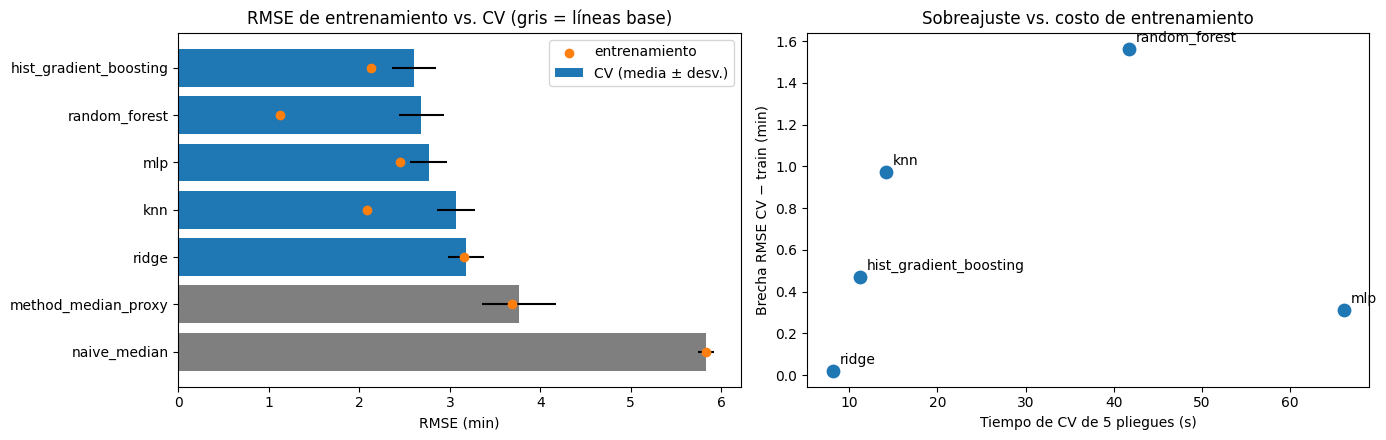

In [3]:
import matplotlib.pyplot as plt
import numpy as np

learning_rates = {"hist_gradient_boosting": "0.1 (learning_rate)", "mlp": "0.001 (learning_rate_init, adam)"}
results_table = pd.concat([baseline_table, candidate_table], ignore_index=True)
results_table["learning_rate"] = results_table["family"].map(learning_rates).fillna("no aplica")
results_table["brecha_%"] = 100 * results_table["rmse_train_cv_gap"] / results_table["cv_rmse_mean"]
results_table["cv_rmse"] = results_table.apply(lambda r: f"{r.cv_rmse_mean:.3f} ± {r.cv_rmse_std:.3f}", axis=1)
display(results_table[["phase", "family", "train_rmse_mean", "cv_rmse", "rmse_train_cv_gap", "brecha_%", "cv_mae_mean", "learning_rate", "cv_fit_seconds_total"]].round(3))

best_baseline = baseline_table["cv_rmse_mean"].min()
beats = candidate_table.assign(
    supera_dummy=candidate_table["cv_rmse_mean"] < baseline_table.set_index("family").loc["naive_median", "cv_rmse_mean"],
    supera_negocio=candidate_table["cv_rmse_mean"] < baseline_table.set_index("family").loc["method_median_proxy", "cv_rmse_mean"],
)
display(beats[["family", "cv_rmse_mean", "supera_dummy", "supera_negocio"]].round(3))
print("Todos los candidatos superan ambas líneas base:", bool(beats[["supera_dummy", "supera_negocio"]].all().all()))

ordered = results_table.sort_values("cv_rmse_mean")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ypos = np.arange(len(ordered))
axes[0].barh(ypos, ordered["cv_rmse_mean"], xerr=ordered["cv_rmse_std"], color=["tab:gray" if p == "baseline" else "tab:blue" for p in ordered["phase"]], label="CV (media ± desv.)")
axes[0].scatter(ordered["train_rmse_mean"], ypos, color="tab:orange", zorder=3, label="entrenamiento")
axes[0].set_yticks(ypos, ordered["family"])
axes[0].invert_yaxis()
axes[0].set(xlabel="RMSE (min)", title="RMSE de entrenamiento vs. CV (gris = líneas base)")
axes[0].legend()
models_only = candidate_table
axes[1].scatter(models_only["cv_fit_seconds_total"], models_only["rmse_train_cv_gap"], s=80)
for _, row in models_only.iterrows():
    axes[1].annotate(row["family"], (row["cv_fit_seconds_total"], row["rmse_train_cv_gap"]), textcoords="offset points", xytext=(5, 5))
axes[1].set(xlabel="Tiempo de CV de 5 pliegues (s)", ylabel="Brecha RMSE CV − train (min)", title="Sobreajuste vs. costo de entrenamiento")
plt.tight_layout()
plt.show()

### Diagnóstico de sobreajuste

| Familia | Lectura de la brecha | Diagnóstico |
|---|---|---|
| Random Forest | train ≈ 1,12 vs. CV ≈ 2,68 min (brecha ≈ 1,56) | **Sobreajuste fuerte**: los árboles profundos memorizan compuestos que no reaparecen en la validación agrupada. El tuning debe limitar profundidad u hojas. |
| KNN | brecha ≈ 0,97 | Sobreajuste moderado: con k=5 copia la retención de vecinos muy parecidos. |
| HistGradientBoosting | brecha ≈ 0,47 | Equilibrio razonable: el mejor CV con una brecha contenida. |
| MLP | brecha ≈ 0,31, con `ConvergenceWarning` a 200 iteraciones | Infraajuste por falta de convergencia más que sobreajuste. |
| Ridge | brecha ≈ 0,02 y CV ≈ 3,18 | **Sesgo alto**: un modelo lineal no captura la interacción molécula × método. |

Los tres mejores por RMSE CV (HGB, RF y MLP) pasan a tuning. Todos los candidatos superan a la línea base ingenua y a la de negocio; Ridge la supera por el margen más pequeño.

## LLM mediante prompting (familia *state of the art*)

Se evaluó **Gemini 3.5 Flash-Lite** en modo *zero-shot* con `scripts/run_llm_benchmark.py` (`src/llm_benchmark.py`). El prompt envía solo el SMILES y las condiciones cromatográficas (fases A/B y flujo) y pide un único número en minutos. **No se envían el tiempo real, InChIKey ni nombres.**

- **Muestra:** 50 compuestos distintos del holdout (semilla 42). Un LLM no se puede ajustar ni validar con GroupKFold sin miles de llamadas a una API de pago, por lo que su resultado **no es comparable con el CV de la tabla anterior** y se reporta aparte.
- **Momento:** se ejecutó después de elegir champion/challenger y **no influyó en la selección**. En la misma muestra se reportan los dos modelos registrados como referencia.
- **Trazabilidad:** la corrida está en MLflow con `phase=llm_benchmark`; las respuestas y métricas están en `docs/llm_benchmark_*`.

{'archivo': 'llm_benchmark_metrics_20261118T013622Z.json', 'modelo': 'gemini-3.5-flash-lite', 'n': 50, 'target_enviado_al_proveedor': False, 'mlflow_run': '5a1907598abf485690cdd74b57557b3e', 'fase': 'llm_benchmark', 'estado': 'FINISHED'}


,RMSE (min),MAE (min)
Gemini zero-shot,5.344,4.528
champion (HGB),2.064,1.302
challenger (RF),2.103,1.360


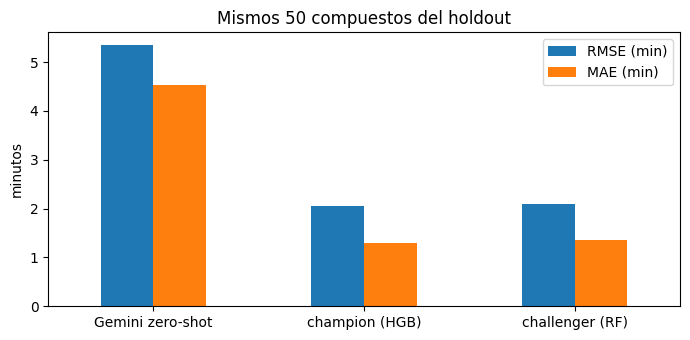

In [4]:
import json
from mlflow.tracking import MlflowClient
from src.experiments import configure_tracking

configure_tracking()
llm_metrics_path = sorted((PROJECT_ROOT / "docs").glob("llm_benchmark_metrics_*.json"))[-1]
llm_report = json.loads(llm_metrics_path.read_text())
llm_run = MlflowClient().get_run(llm_report["mlflow_run_id"])
print({"archivo": llm_metrics_path.name, "modelo": llm_report["model"], "n": llm_report["sample_size"],
       "target_enviado_al_proveedor": llm_report["target_labels_sent_to_provider"],
       "mlflow_run": llm_run.info.run_id, "fase": llm_run.data.tags.get("phase"), "estado": llm_run.info.status})
m = llm_report["metrics"]
llm_table = pd.DataFrame({
    "RMSE (min)": [m["gemini_rmse_min"], m["champion_rmse_min"], m["challenger_rmse_min"]],
    "MAE (min)": [m["gemini_mae_min"], m["champion_mae_min"], m["challenger_mae_min"]],
}, index=["Gemini zero-shot", "champion (HGB)", "challenger (RF)"])
display(llm_table.round(3))
llm_table.plot(kind="bar", figsize=(7, 3.5), rot=0, title=f"Mismos {llm_report['sample_size']} compuestos del holdout")
plt.ylabel("minutos")
plt.tight_layout()
plt.show()

**Hallazgo:** el LLM *zero-shot* duplica con creces el error de los modelos tabulares (RMSE ≈ 5,3 vs. ≈ 2,1 min) y queda cerca de la línea base ingenua (CV ≈ 5,8 min). Además, con 50 compuestos la incertidumbre es alta y Gemini pudo haber visto RepoRT en su preentrenamiento, así que el resultado es exploratorio. No se considera para producción: es más lento, tiene costo por llamada, no es determinista entre versiones y no ofrece explicación verificable.